
# Pitch Basics

First we import the Pitch classes and matplotlib


In [1]:
!pip install mplsoccer pandas-summary

import matplotlib.pyplot as plt

from mplsoccer import Pitch, VerticalPitch

plt.rcdefaults() # cancel the xqcd

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 kB 10.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.4/159.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.4/79.4 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 61.7 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 61.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 21.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 59.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.7/34.7 MB 50.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 78.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.1/294.1 kB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 63.2 MB/s eta 0:00:00

## Draw a pitch on a new axis
Let's plot on a new axis first.



In [2]:
# import csv

# # Define the path to your CSV file
# csv_file_path = 'Session-Mateo-gps.csv'

# # Initialize an empty list to store the data
# sheet = []

# # Open and read the CSV file
# with open(csv_file_path, 'r') as file:
#     csv_reader = csv.reader(file)
#     header = next(csv_reader)  # Read the header row (if it exists)
#     sheet.append(header)  # Add the header to the data list (optional)
    
#     for row in csv_reader:
#         sheet.append(row)

# # Display the data
# for row in sheet[:10]:
#     print(row)

In [4]:
import pandas as pd
# csv_file_path = 'Session-28-10-2023-trimmed.csv'
csv_file_path = 'Session_28-10-2023.csv'
df = pd.read_csv(csv_file_path)
df.columns = ['Player Display Name', 'Time', 'Elapsed Time (s)', 'Lat', 'Lon', 'Speed km/h', 'Instantaneous Acceleration Impulse', 'Heart Rate (bpm)', 'basura']
df.columns = df.columns.str.strip()

#https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu
# -34.794926, -56.148368
# -34.795816, -56.147428

lat_lower_bound = -34.795816
lat_upper_bound = -34.794926
lon_lower_bound = -56.148368
lon_upper_bound = -56.147428
fix_df = df[(df['Lat'] > lat_lower_bound) & (df['Lat'] < lat_upper_bound)]
fix_df = fix_df[(fix_df['Lon'] > lon_lower_bound) & (fix_df['Lon'] < lon_upper_bound)]

In [5]:
fix_df

,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura
42,Fran Dennis,11:04:41.60,1622.400002,-34.794928,-56.147491,5.830005,4.900004,0,NaN
42,Fran Dennis,11:04:41.70,1622.500001,-34.794929,-56.147491,5.730005,1.000001,0,NaN
42,Fran Dennis,11:04:41.80,1622.600001,-34.794930,-56.147491,5.590004,1.400001,0,NaN
42,Fran Dennis,11:04:41.90,1622.700000,-34.794932,-56.147491,5.410004,1.800001,0,NaN
42,Fran Dennis,11:04:42.00,1622.800000,-34.794933,-56.147491,5.300004,1.100001,0,NaN
...,...,...,...,...,...,...,...,...,...
166,Rodriguez Luciano,13:32:19.00,59539.000000,-34.795800,-56.147849,15.730013,0.300000,45,NaN
166,Rodriguez Luciano,13:32:19.10,59539.100000,-34.795804,-56.147850,15.710013,0.200000,45,NaN
166,Rodriguez Luciano,13:32:19.20,59539.199999,-34.795808,-56.147851,15.690013,0.200000,45,NaN
166,Rodriguez Luciano,13:32:19.30,59539.299998,-34.795811,-56.147851,15.680013,0.100000,45,NaN



# Analisis Descriptivo


In [6]:
summary_lon = fix_df['Lon'].describe()
summary_lat = fix_df['Lat'].describe()

print("summary_lon:\n", summary_lon)
print("summary_lat:\n", summary_lat)

summary_lon:
 count    552749.000000
mean        -56.147823
std           0.000203
min         -56.148344
25%         -56.147964
50%         -56.147832
75%         -56.147671
max         -56.147428
Name: Lon, dtype: float64
summary_lat:
 count    552749.000000
mean        -34.795362
std           0.000204
min         -34.795816
25%         -34.795511
50%         -34.795362
75%         -34.795196
max         -34.794926
Name: Lat, dtype: float64


In [7]:
from pandas_summary import DataFrameSummary

# Get a summary of the DataFrame

numeric_columns = fix_df.select_dtypes(include=['number'])

summary = DataFrameSummary(numeric_columns)

# Print the summary
print(summary.summary())

             Elapsed Time (s)        Lat        Lon Speed km/h  \
count                552749.0   552749.0   552749.0   552749.0   
mean             20305.831054 -34.795362 -56.147823   5.516483   
std              23083.770263   0.000204   0.000203   4.711358   
min               1259.700008 -34.795816 -56.148344        0.0   
25%               3593.000004 -34.795511 -56.147964   2.560002   
50%                    6307.1 -34.795362 -56.147832   4.590004   
75%              52016.199995 -34.795196 -56.147671   6.690005   
max              59539.399998 -34.794926 -56.147428  43.110034   
counts                 552749     552749     552749     552749   
uniques                251486       5339       5391       2916   
missing                     0          0          0          0   
missing_perc               0%         0%         0%         0%   
types                 numeric    numeric    numeric    numeric   

             Instantaneous Acceleration Impulse Heart Rate (bpm)   basura  

In [8]:
# Get the minimum and maximum values for 'Column1'
min_value_lat = fix_df['Lat'].min()
max_value_lat = fix_df['Lat'].max()

# Get the minimum and maximum values for 'Column2'
min_value_lon = fix_df['Lon'].min()
max_value_lon = fix_df['Lon'].max()

print(f"Minimum of player min_value_lat: {min_value_lat}")
print(f"Maximum of player max_value_lat: {max_value_lat}")
print(f"Minimum of player min_value_lon: {min_value_lon}")
print(f"Maximum of player max_value_lon: {max_value_lon}")

Minimum of player min_value_lat: -34.79581583
Maximum of player max_value_lat: -34.79492617
Minimum of player min_value_lon: -56.148344
Maximum of player max_value_lon: -56.14742817


In [9]:
# puntos en cancha
# https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu

# -34.794926, -56.148368
# -34.795816, -56.147428

# Coordenadas de Los cespedes
lat_min = -34.795816
lat_max = -34.794926
lon_min = -56.148368
lon_max = -56.147428


# Trigonometria


In [10]:
import numpy as np

# Define the GPS coordinates of four points (A, B, C, D) on the field
point_A = (-34.794927, -56.148375)
point_B = (-34.794853, -56.147571)
point_C = (-34.795902, -56.148234)
point_D = (-34.795815, -56.147426)

# Calculate the length and width of the rectangle
length = np.sqrt((point_A[0] - point_B[0])**2 + (point_A[1] - point_B[1])**2)
width = np.sqrt((point_A[0] - point_C[0])**2 + (point_A[1] - point_C[1])**2)

# Determine which sides are length and width
if length > width:
    length, width = width, length  # Swap if necessary

# Calculate the angle between the length side and the North direction
rotation_angle_radians = np.arctan2(point_B[1] - point_A[1], point_B[0] - point_A[0])
rotation_angle_degrees = np.degrees(rotation_angle_radians)

# Ensure the angle is positive (between 0 and 360 degrees)
if rotation_angle_degrees < 0:
    rotation_angle_degrees += 360

print(f"Rotation Angle: {rotation_angle_degrees} degrees")

Rotation Angle: 84.74132377744776 degrees



# Normalizacion de las coordenadas para el Pitch


In [11]:
import pandas as pd
import numpy as np

# Define the rotation angle in degrees
rotation_angle_degrees = 90 - 84.74132377744776  # Degrees rotated from North to West

# Convert the rotation angle to radians
rotation_angle_radians = np.radians(rotation_angle_degrees)

# Define the size of the soccer field in meters
soccer_field_length = 80  # In meters
soccer_field_width = 120  # In meters

# Function to apply the rotation to coordinates
def rotate_coordinates(row):
    lat, lon = row['Lat'], row['Lon']
    new_lat = lat * np.cos(rotation_angle_radians) - lon * np.sin(rotation_angle_radians)
    new_lon = lat * np.sin(rotation_angle_radians) + lon * np.cos(rotation_angle_radians)
    return pd.Series({'Lat': new_lat, 'Lon': new_lon})


df = fix_df
# Apply the rotation to the coordinates
df[['Lat', 'Lon']] = df.apply(rotate_coordinates, axis=1)

# Scale and normalize the coordinates to the soccer field dimensions
df['Lat_normalized'] = (df['Lat'] - df['Lat'].min()) / (df['Lat'].max() - df['Lat'].min()) * soccer_field_length
df['Lon_normalized'] = (df['Lon'] - df['Lon'].min()) / (df['Lon'].max() - df['Lon'].min()) * soccer_field_width


# Display the DataFrame with normalized coordinates
df.head()


,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura,Lat_normalized,Lon_normalized
42,Fran Dennis,11:04:41.60,1622.400002,-29.502425,-59.100208,5.830005,4.900004,0,NaN,75.145144,112.612317
42,Fran Dennis,11:04:41.70,1622.500001,-29.502426,-59.100209,5.730005,1.000001,0,NaN,75.019975,112.574769
42,Fran Dennis,11:04:41.80,1622.600001,-29.502428,-59.100209,5.590004,1.400001,0,NaN,74.892167,112.578662
42,Fran Dennis,11:04:41.90,1622.700000,-29.502429,-59.100209,5.410004,1.800001,0,NaN,74.765678,112.561835
42,Fran Dennis,11:04:42.00,1622.800000,-29.502431,-59.100209,5.300004,1.100001,0,NaN,74.636628,112.585230


In [12]:
df_backed_up = df


# Visualizacion

### Partido completo, segmentado cada 100


552749


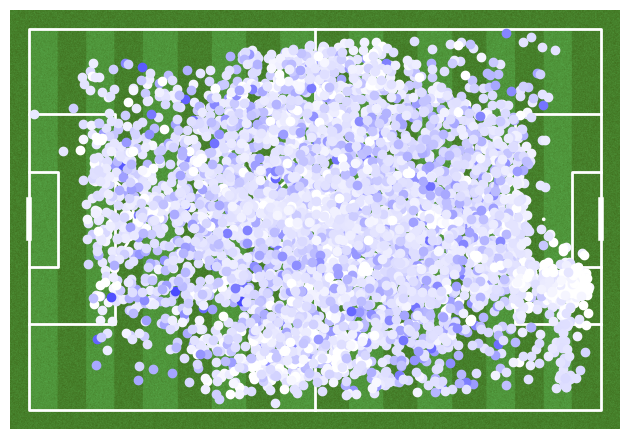

In [13]:
from mplsoccer import Pitch, VerticalPitch

pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
fig, ax = pitch.draw()


print(len(df))

# cancha: 120x80

step = 100
colors = np.linspace(0, 1, len(df))
# Iterar avanzando de 10 en 10 elementos
for i in range(0, len(df), step):
    # color = (1, 1 - colors[i], 1 - colors[i])
    for index, row in df.iloc[i:i+1].iterrows():
        # print(row['Lat_normalized'],row['Lon_normalized'])
        speed = row['Speed km/h']
        normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
        color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
        ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)


### Primeros minutos

In [14]:
df.iloc[0]

Player Display Name                   Fran Dennis 
Time                                   11:04:41.60
Elapsed Time (s)                       1622.400002
Lat                                     -29.502425
Lon                                     -59.100208
Speed km/h                                5.830005
Instantaneous Acceleration Impulse        4.900004
Heart Rate (bpm)                                 0
basura                                         NaN
Lat_normalized                           75.145144
Lon_normalized                          112.612317
Name: 42, dtype: object

In [15]:
df.iloc[1]

Player Display Name                   Fran Dennis 
Time                                   11:04:41.70
Elapsed Time (s)                       1622.500001
Lat                                     -29.502426
Lon                                     -59.100209
Speed km/h                                5.730005
Instantaneous Acceleration Impulse        1.000001
Heart Rate (bpm)                                 0
basura                                         NaN
Lat_normalized                           75.019975
Lon_normalized                          112.574769
Name: 42, dtype: object

In [16]:
# import pandas as pd

# def encontrar_intervalos_coexistencia(df):
#     # Agrupar por tiempo y obtener la lista de jugadores en cada grupo
#     grupos = df.groupby('Elapsed Time (s)')['Player Display Name'].apply(list)
    
#     # Encontrar los intervalos donde todos los jugadores están presentes
#     intervalos_coexistencia = [intervalo for intervalo, jugadores in grupos.items() if set(df['Player Display Name'].unique()) == set(jugadores)]
    
#     return intervalos_coexistencia

# intervalos_coexistencia = encontrar_intervalos_coexistencia(df)
# print("Intervalos de coexistencia:", intervalos_coexistencia)

grupos = df.groupby('Elapsed Time (s)')['Player Display Name'].apply(list)

In [17]:
for intervalo, jugadores in grupos.items():
    if len(jugadores) > 8:
        print(intervalo, jugadores)

1851.60000384785 ['Facundo Dominguez ', 'Facundo Dominguez ', 'Facundo Dominguez ', 'Mateo Soria ', 'Mateo Soria ', 'Mateo Soria ', 'Roman ', 'Roman ', 'Roman ']
2056.4000063343 ['Facundo Dominguez ', 'Facundo Dominguez ', 'Facundo Dominguez ', 'Mateo Soria ', 'Mateo Soria ', 'Mateo Soria ', 'Roman ', 'Roman ', 'Roman ']
2158.69999963325 ['Fran Dennis ', 'Fran Dennis ', 'Fran Dennis ', 'Mauro Martinez ', 'Sebastian Mysznajes', 'Sebastian Mysznajes', 'Sebastian Mysznajes', 'Rodrigo Espalter ', 'Mateo Soria ']
2261.20000064839 ['Facundo Dominguez ', 'Facundo Dominguez ', 'Facundo Dominguez ', 'Rodrigo Espalter ', 'Rodrigo Espalter ', 'Rodrigo Espalter ', 'Roman ', 'Roman ', 'Roman ']
2568.40000406373 ['Facundo Dominguez ', 'Facundo Dominguez ', 'Facundo Dominguez ', 'Mateo Soria ', 'Mateo Soria ', 'Mateo Soria ', 'Roman ', 'Roman ', 'Roman ']
2875.49999984913 ['Fran Dennis ', 'Fran Dennis ', 'Fran Dennis ', 'Mauro Martinez ', 'Facundo Dominguez ', 'Sebastian Mysznajes', 'Sebastian Myszna

# Visualizacion por minuto de juego

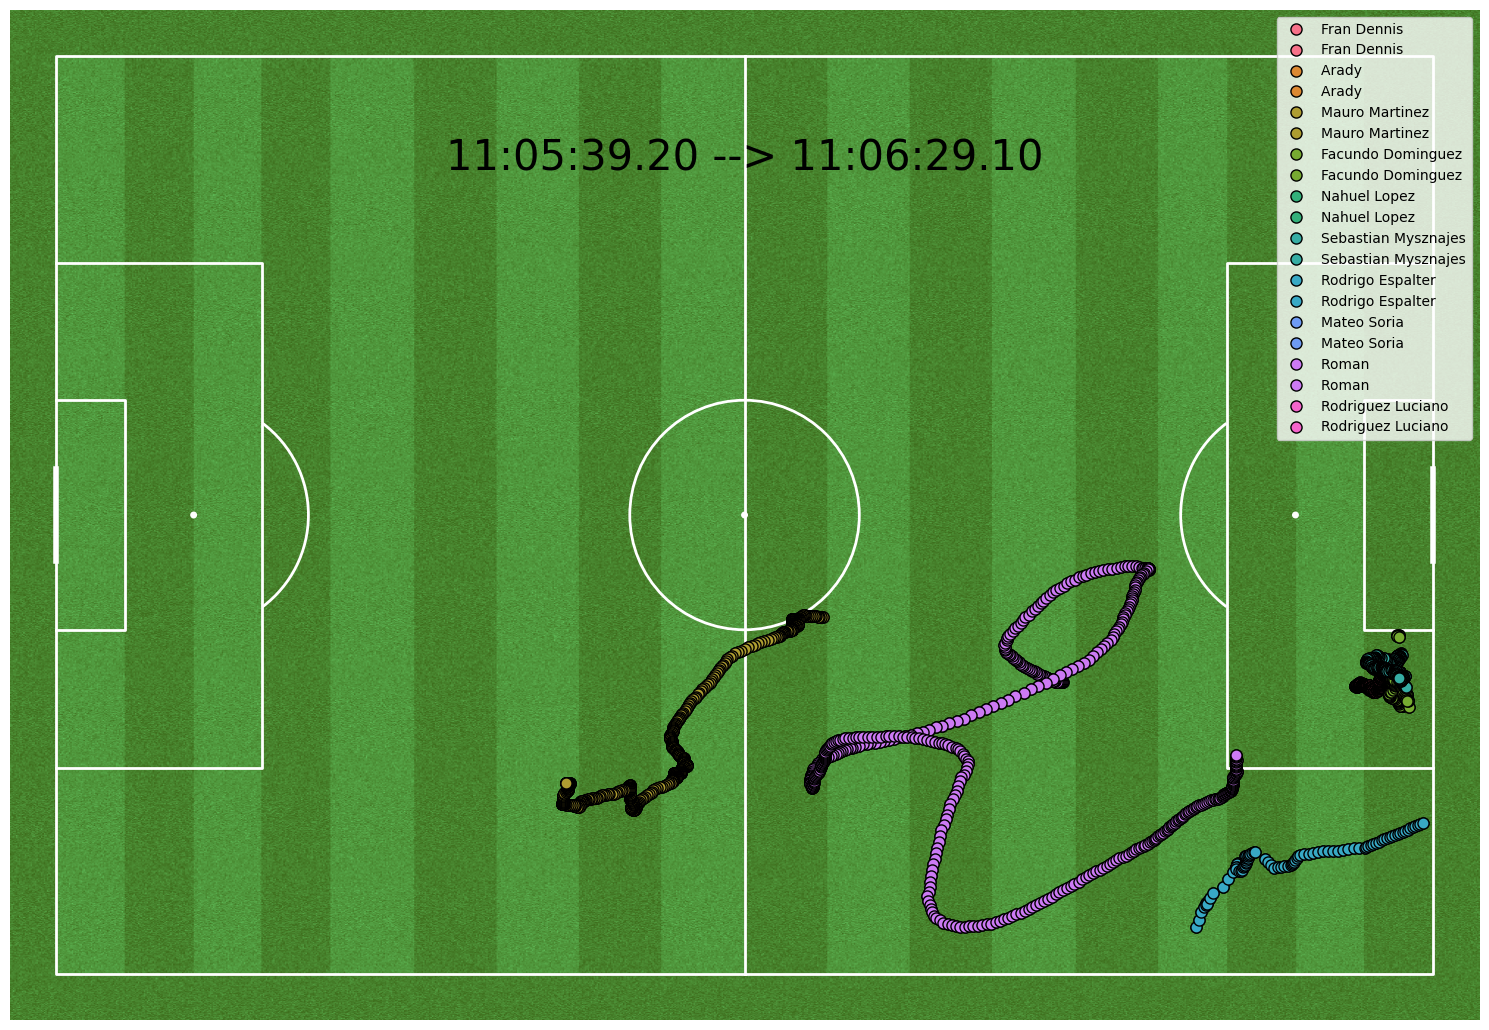

In [74]:
from matplotlib import animation
from matplotlib import pyplot as plt
import seaborn as sns

# https://mplsoccer.readthedocs.io/en/latest/gallery/pitch_plots/plot_animation.html

# First set up the figure, the axis
pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
fig, ax = pitch.draw(figsize=(16, 10.4))

# then setup the pitch plot markers we want to animate
marker_kwargs = {'marker': 'o', 'markeredgecolor': 'black', 'linestyle': 'None'}
paleta_colores = sns.color_palette("husl", n_colors=len(df['Player Display Name'].unique()))

# Crear un diccionario que asocie cada jugador con un color de la paleta
# colores = dict(zip(df['Player Display Name'].unique(), paleta_colores))


# print(colores)

# animation function
def animate(i):
    """ Function to animate the data. Each frame it sets the data for the players and the ball."""
    # set the ball data with the x and y positions for the ith frame
    # get the frame id for the ith frame
    return ax.plot(player_df[['Lon_normalized']], player_df[['Lat_normalized']], ms=8, label=player, markerfacecolor=colores[player], zorder=1, **marker_kwargs)
    
segundo = 1680
window = 50
time_min = None
time_max = None

# call the animator, animate so 25 frames per second
for player in df['Player Display Name'].unique():
    player_df = df[(df['Player Display Name'] == player) & (df['Elapsed Time (s)'] > segundo) & (df['Elapsed Time (s)'] < segundo + window)]
    if time_min is None:
        time_min = min(player_df["Time"])
        time_max = max(player_df["Time"])
    animation.FuncAnimation(fig, animate, blit=True)
    ax.legend()

annotation = ax.annotate(f'{time_min} --> {time_max}', (60, 10), fontsize=30, ha='center')

plt.show()


## Segundo a segundo

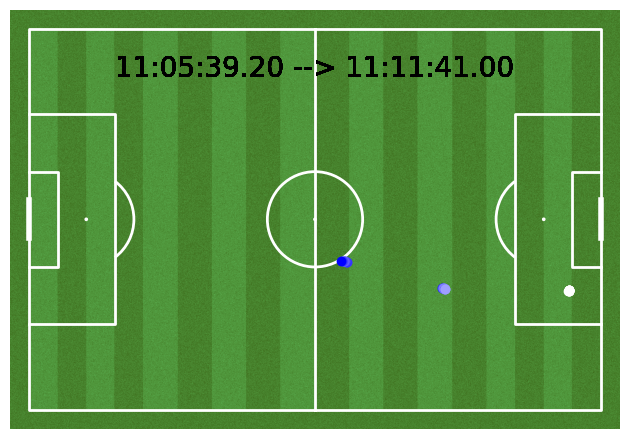

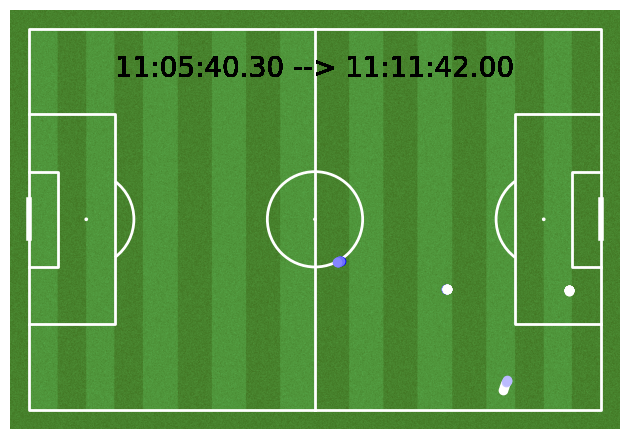

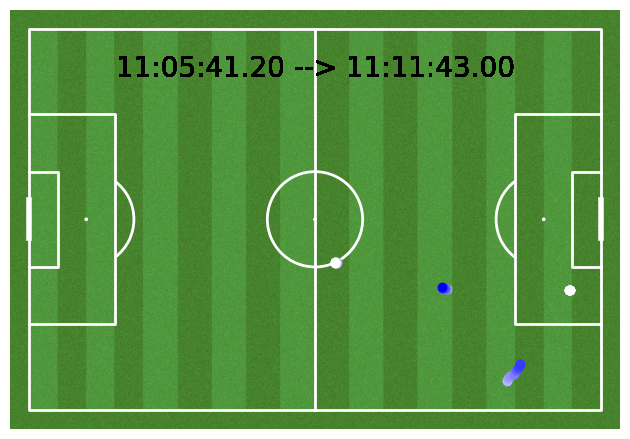

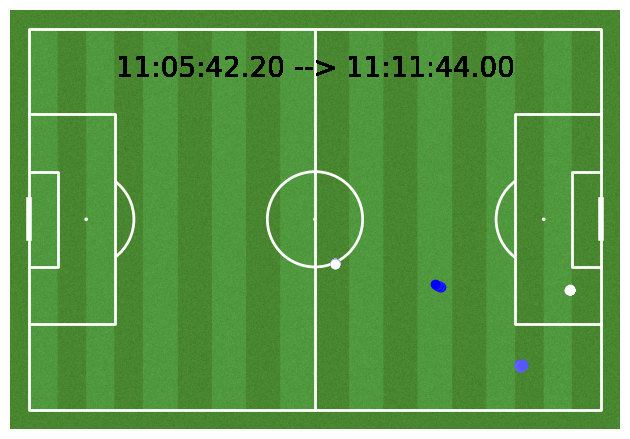

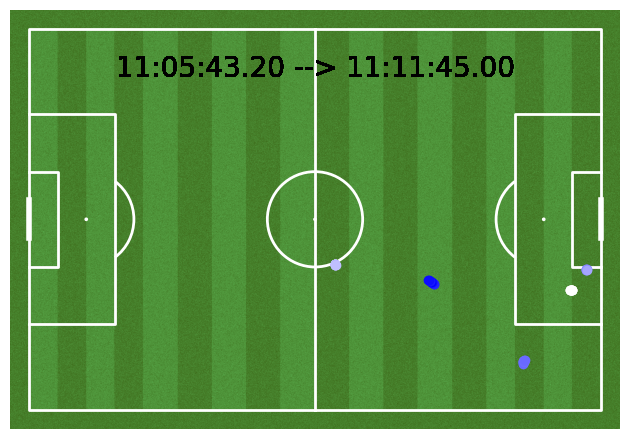

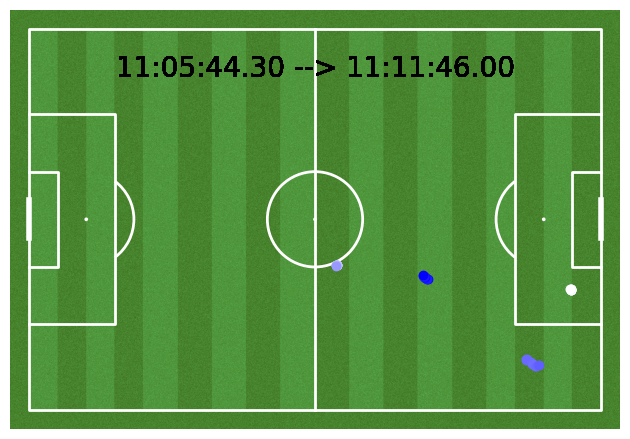

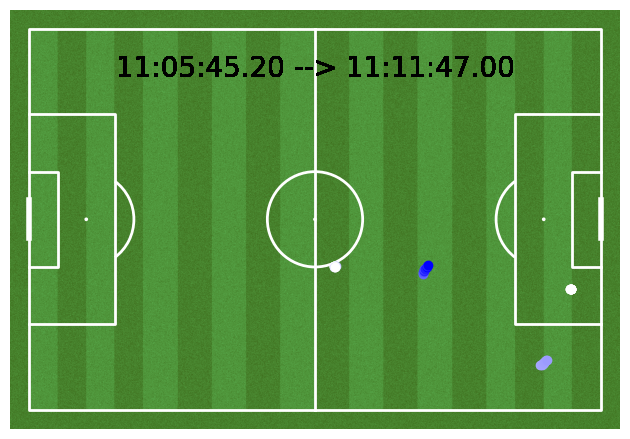

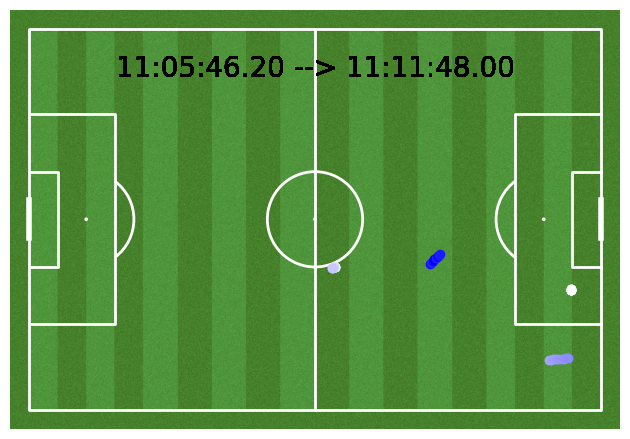

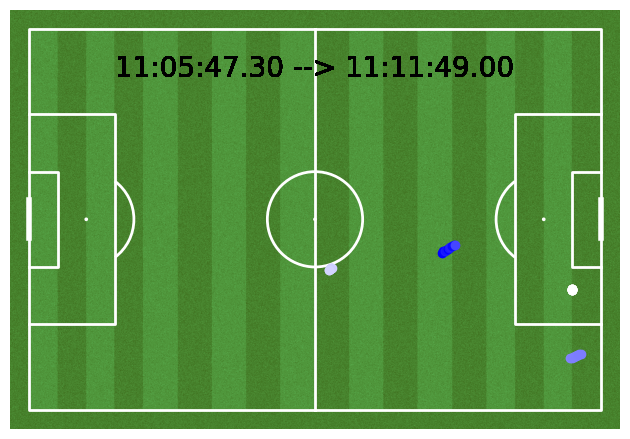

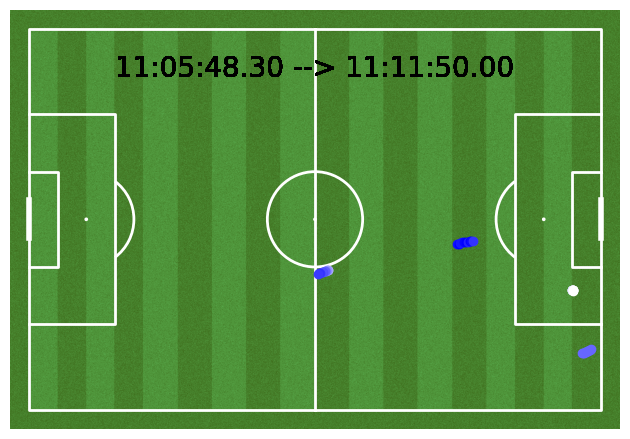

In [78]:
from mplsoccer import Pitch, VerticalPitch


# custom attempt

pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
segundo = 1680

while segundo < 1690:

    fig, ax = pitch.draw()
    
    
    t0 = df[df['Elapsed Time (s)'] > segundo] 
    t0 = t0[t0['Elapsed Time (s)'] < segundo + 1]
    t0
    
    # print(len(t0))
    # print(t0)
    
    # cancha: 120x80
    
    step = 1
    colors = np.linspace(0, 1, len(t0))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(t0), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        time_min = None
        time_max = None
        for index, row in t0.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - t0['Speed km/h'].min()) / (t0['Speed km/h'].max() - t0['Speed km/h'].min())
            color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)
            if time_min is None:
                time_min = min(t0["Time"])
                time_max = max(t0["Time"])
            annotation = ax.annotate(f'{time_min} --> {time_max}', (60, 10), fontsize=20, ha='center')

    segundo+=1

In [79]:
speed_df = fix_df[fix_df['Speed km/h'] > 0.5]

In [80]:
def plot_velocidades_altas(v_min, subtitle=None ,use_df=None, v_max=None, color_param='R', step=1):
    pitch = Pitch(pitch_color='#aabb97', line_color='white',
              stripe_color='#c2d59d', stripe=True)  # optional stripes
    fig, ax = pitch.draw()
    if use_df is not None:
        fix_df = use_df 
    
    speed_df = fix_df[fix_df['Speed km/h'] > v_min]
    str = f'Velocidades > {v_min}km/h'
    
    if v_max:
        speed_df = speed_df[speed_df['Speed km/h'] < v_max]
        str = f'{str} y < {v_max}km/h'
    
    df = speed_df
    
    print(subtitle, "Total de puntos: ", len(df))
    annotation = ax.annotate(str, (60, 10), fontsize=20, ha='center', color="green")
    annotation_2 = ax.annotate(subtitle, (60, 20), fontsize=10, ha='center', color="green")
    
    # cancha: 120x80
    colors = np.linspace(0, 1, len(df))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(df), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        for index, row in df.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
            if color_param == 'R':
                color = (1 - normalized_speed, 0, 0)  # Rojo
            elif color_param == 'G':
                color = (0, 1 - normalized_speed, 0)  # Verde
            elif color_param == 'B':
                color = (0, 0, 1 - normalized_speed)  # Azul
            else:
                color = (1, 1, 1)  # Blanco por defecto
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)

In [81]:
# plot_velocidades_altas(25)

In [82]:
# plot_velocidades_altas(20, v_max=25, color_param='B', step=2)

In [83]:
# plot_velocidades_altas(15, v_max=20, color_param='G', step=3)

# Mapa de calor del partido

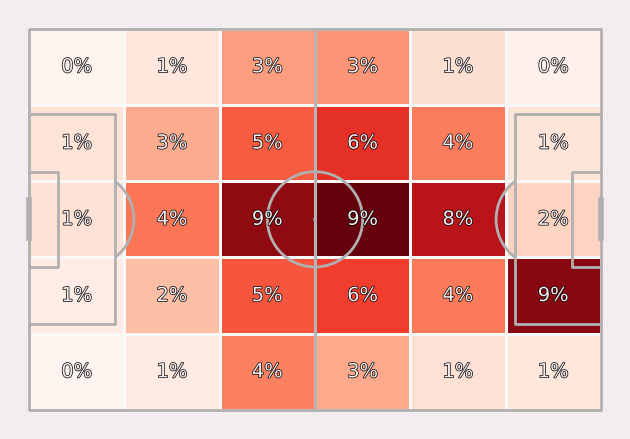

In [84]:
import matplotlib.patheffects as path_effects

path_eff = [path_effects.Stroke(linewidth=1, foreground='black'),
            path_effects.Normal()]

pitch = Pitch(pitch_type='statsbomb', line_zorder=2, pitch_color='#f4edf0')
fig, ax = pitch.draw()
fig.set_facecolor('#f4edf0')

df = fix_df

bin_statistic = pitch.bin_statistic(df['Lon_normalized'], df['Lat_normalized'], statistic='count', bins=(6, 5), normalize=True)
pitch.heatmap(bin_statistic, ax=ax, cmap='Reds', edgecolor='#f9f9f9')
labels = pitch.label_heatmap(bin_statistic, color='#f4edf0', fontsize=14,
                             ax=ax, ha='center', va='center',
                             str_format='{:.0%}', path_effects=path_eff)

# Analisis de Distancias

In [85]:
import math

df = fix_df
df = df[df['Elapsed Time (s)'] > 0]

# Apply the rotation to the coordinates
df['coord'] = list(zip(df['Lat'], df['Lon'], df['Elapsed Time (s)']))
# Sample GPS coordinate data (latitude, longitude, timestamp)
gps_data = df['coord']

# Function to calculate distance between two GPS coordinates
def calculate_distance(coord1, coord2):
    lat1, lon1, _ = coord1
    lat2, lon2, _ = coord2
    radius = 6371  # Earth's radius in kilometers
    lat1_rad = math.radians(lat1)
    lon1_rad = math.radians(lon1)
    lat2_rad = math.radians(lat2)
    lon2_rad = math.radians(lon2)
    delta_lat = lat2_rad - lat1_rad
    delta_lon = lon2_rad - lon1_rad
    a = math.sin(delta_lat / 2)**2 + math.cos(lat1_rad) * math.cos(lat2_rad) * math.sin(delta_lon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    distance = radius * c
    return distance

# Threshold speed in km/h
threshold_speed = 20

# Variables to keep track of total distance and distance above threshold
total_distance = 0
distance_above_threshold = 0

for i in range(len(df) - 1):
    coord1 = df['coord'].iloc[i]
    coord2 = df['coord'].iloc[i + 1]

    # Calculate the distance between two consecutive coordinates
    distance = calculate_distance(coord1, coord2)

    # Calculate the time elapsed between coordinates (in seconds)
    time_elapsed = 0.1 
    # time_elapsed ----> coord2[2] - coord1[2]
    # print(time_elapsed)

    # Calculate speed (distance / time) in km/h
    speed = (distance / time_elapsed) * 3600

    # Update total distance
    total_distance += distance

    # Check if speed is above the threshold
    if speed >= threshold_speed:
        distance_above_threshold += distance

print(f"Total distance run: {total_distance} km")
print(f"Distance above {threshold_speed} km/h: {distance_above_threshold} km")

Total distance run: 90.0058832687209 km
Distance above 20 km/h: 8.144766502335907 km


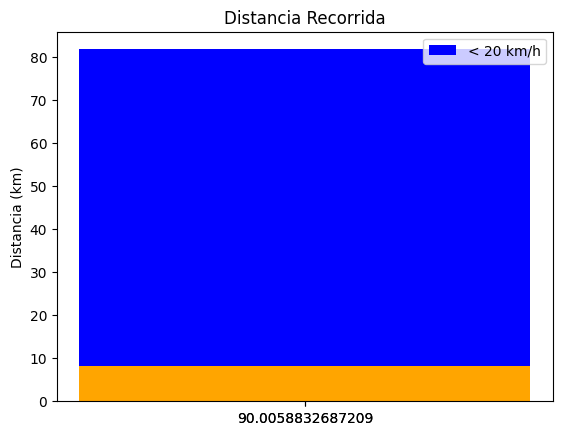

In [86]:
import matplotlib.pyplot as plt

# Distancia recorrida por debajo de threshold_speed km/h
distance_below_threshold = total_distance - distance_above_threshold

# Colores para los segmentos
colors = ['blue', 'orange']

# Etiquetas para los segmentos
labels = [f'< {threshold_speed} km/h', f'>= {threshold_speed} km/h']

# Alturas de los segmentos
heights = [distance_below_threshold, distance_above_threshold]

# Posiciones en el eje X para los segmentos
positions = [0, 0]

# Crear la figura y los ejes
fig, ax = plt.subplots()

# Dibujar el segmento de la barra
ax.bar(positions, heights, color=colors, tick_label=[total_distance])

# Configurar el eje y
ax.set_ylabel('Distancia (km)')

# Configurar el título
ax.set_title('Distancia Recorrida')

# Añadir una leyenda
ax.legend(labels)

# Mostrar la gráfica
plt.show()

# Umbral de Aceleraciones / Velocidades por jugador

In [87]:
import pandas as pd


# Crear un DataFrame de ejemplo con coordenadas y velocidad
df = fix_df

# km/h => m/s
df['Speed m/s'] = list(df['Speed km/h']/3.6)
# df['Acceleration'] = list(df['Speed km/h']/3.6)

# Umbral de aceleración
threshold_acceleration = 4.9  # Ajusta el umbral según sea necesario


# Contador de veces que se supera el umbral de aceleración
count_exceeding_threshold = 0

rows_per_second = 10

when = []

# Iterar a través del DataFrame con saltos de 10 filas
for i in range(0, len(df) - rows_per_second, rows_per_second):
    # Obtener la velocidad actual y la velocidad anterior
    velocity_current = df['Speed m/s'].iloc[i]
    velocity_next = df['Speed m/s'].iloc[i + rows_per_second]

    # Calcular la aceleración como cambio en la velocidad dividido por el tiempo (1 segundo)
    acceleration = (velocity_next - velocity_current) / 1.0

    # Comparar la aceleración con el umbral
    if acceleration > threshold_acceleration:
        when.append([i])
        count_exceeding_threshold += 1

print(f"El umbral de aceleración se superó {count_exceeding_threshold} veces.")


El umbral de aceleración se superó 1 veces.


In [88]:
when

[[552680]]

In [90]:
def plot_aceleraciones_altas(a_max=3.5, subtitle=None, use_df=None, include_acc=False, color_param='R', step=1):
    
    # Crear un DataFrame de ejemplo con coordenadas y velocidad
    df = use_df
    
    # km/h => m/s
    df['Speed m/s'] = list(df['Speed km/h']/3.6)
    # df['Acceleration'] = list(df['Speed km/h']/3.6)
    
    # Umbral de aceleración
    threshold_acceleration = a_max  # Ajusta el umbral según sea necesario
    
    
    # Contador de veces que se supera el umbral de aceleración
    count_exceeding_threshold = 0
    
    rows_per_second = 10
    
    when = []
    
    # Iterar a través del DataFrame con saltos de 10 filas
    for i in range(0, len(df) - rows_per_second, rows_per_second):
        # Obtener la velocidad actual y la velocidad anterior
        velocity_current = df['Speed m/s'].iloc[i]
        velocity_next = df['Speed m/s'].iloc[i + rows_per_second]
    
        # Calcular la aceleración como cambio en la velocidad dividido por el tiempo (1 segundo)
        acceleration = (velocity_next - velocity_current) / 1.0
        # comment me for perfonmance
        if include_acc:
            df.at[i, 'Acceleration m/s^2'] = acceleration

        # Comparar la aceleración con el umbral
        if acceleration > threshold_acceleration:
            when.append([i])
            count_exceeding_threshold += 1
    
    print(f"El umbral de aceleración se superó {count_exceeding_threshold} veces.")
    
    filas_antes_despues = 10
    
    # DataFrame para almacenar las filas de interés
    df_resultado = pd.DataFrame()
    
    # Iterar a través de los índices de interés
    for indice in when:
        inicio = max(indice[0] - filas_antes_despues, 0)
        fin = min(indice[0] + filas_antes_despues + 1, len(df))
        filas_seleccionadas = df.iloc[inicio:fin]
        df_resultado = pd.concat([df_resultado, filas_seleccionadas])

    
    pitch = Pitch(pitch_color='grass', line_color='white',
                  stripe=True)  # optional stripes
    fig, ax = pitch.draw()

    df = df_resultado
    print(len(df))
    
    # cancha: 120x80
    
    step = 1
    colors = np.linspace(0, 1, len(df))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(df), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        for index, row in df.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
            color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)
    
    
    plt.show()
    return df_resultado

El umbral de aceleración se superó 14 veces.
294


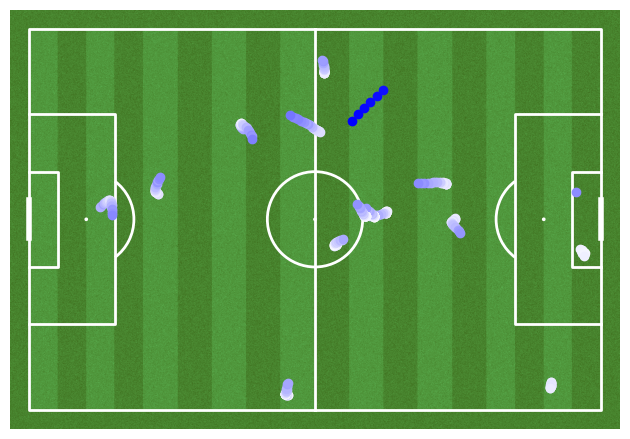

In [91]:
df = plot_aceleraciones_altas(a_max=4, use_df=df_backed_up)

In [92]:
# plot_aceleraciones_altas(a_max=4, use_df=df, include_acc=True)

In [93]:
df.head(100)

,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura,Lat_normalized,Lon_normalized,Speed m/s
42,Fran Dennis,11:07:19.70,1780.500001,-29.502756,-59.100180,2.830002,1.900002,0,NaN,47.090032,116.049809,0.786112
42,Fran Dennis,11:07:19.80,1780.600000,-29.502757,-59.100181,2.660002,1.700001,0,NaN,47.023079,115.979443,0.738889
42,Fran Dennis,11:07:19.90,1780.700000,-29.502758,-59.100181,2.550002,1.100001,0,NaN,46.955649,115.929910,0.708334
42,Fran Dennis,11:07:20.00,1780.799999,-29.502759,-59.100181,2.470002,0.800001,0,NaN,46.838374,115.995434,0.686112
42,Fran Dennis,11:07:20.10,1780.899998,-29.502761,-59.100180,2.660002,1.900002,0,NaN,46.706685,116.060270,0.738889
...,...,...,...,...,...,...,...,...,...,...,...,...
99,Facundo Dominguez,11:33:41.70,3337.800005,-29.503070,-59.100644,11.540009,0.000000,0,NaN,20.528492,59.292639,3.205558
99,Facundo Dominguez,11:33:41.80,3337.900004,-29.503073,-59.100647,12.820010,12.800010,0,NaN,20.294918,58.954270,3.561114
99,Facundo Dominguez,11:33:41.90,3338.000003,-29.503075,-59.100651,16.450013,0.000000,0,NaN,20.072985,58.433073,4.569448
99,Facundo Dominguez,11:33:42.00,3338.100003,-29.503077,-59.100654,14.910012,15.400012,0,NaN,19.886774,58.018650,4.141670


In [94]:
grouped_df = df.groupby('Player Display Name').size()
grouped_df

Player Display Name
Facundo Dominguez     63
Fran Dennis           42
Mauro Martinez        42
Nahuel Lopez          63
Rodrigo Espalter      42
Rodriguez Luciano     42
dtype: int64

In [95]:
# grouped_df['Player Display Name']

Facundo Dominguez  Total de puntos:  0
El umbral de aceleración se superó 2 veces.
42


/tmp/ipykernel_253/1066697871.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Speed m/s'] = list(df['Speed km/h']/3.6)


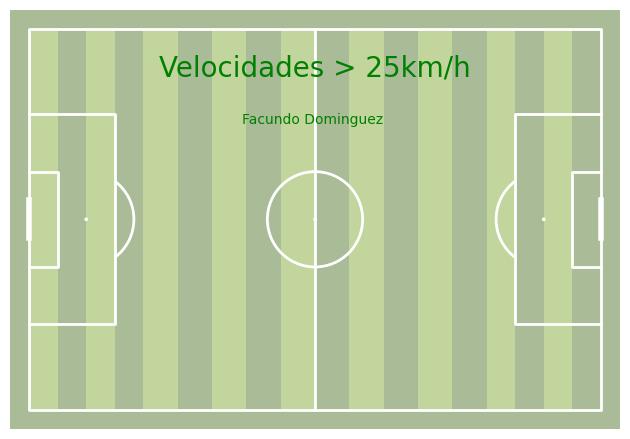

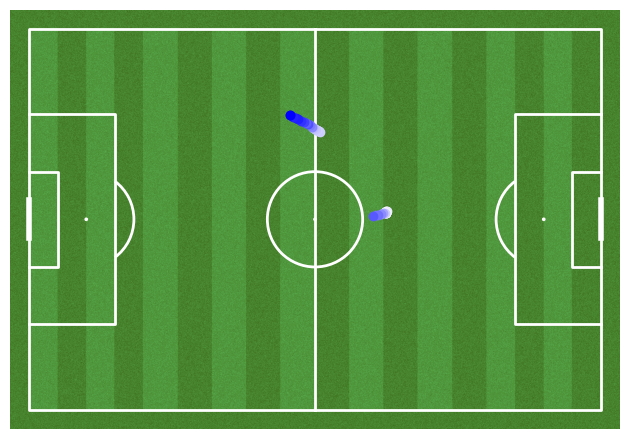

Fran Dennis  Total de puntos:  0
El umbral de aceleración se superó 2 veces.
42


/tmp/ipykernel_253/1066697871.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Speed m/s'] = list(df['Speed km/h']/3.6)


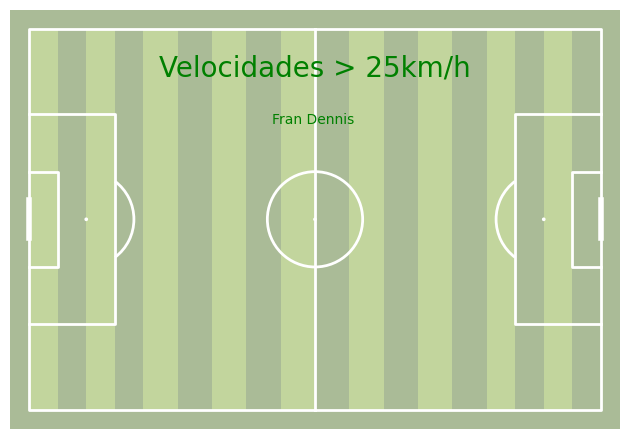

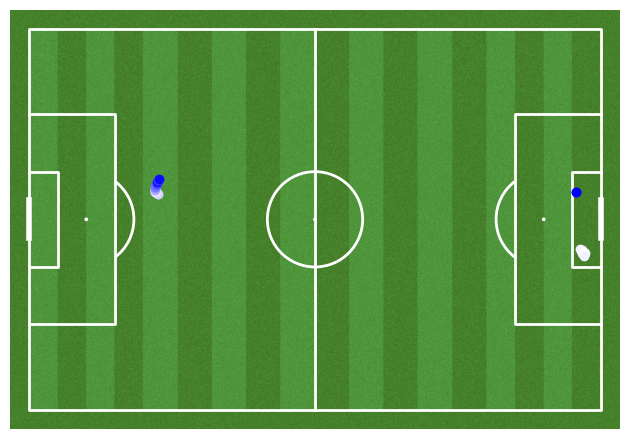

Mauro Martinez  Total de puntos:  0
El umbral de aceleración se superó 2 veces.
42


/tmp/ipykernel_253/1066697871.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Speed m/s'] = list(df['Speed km/h']/3.6)


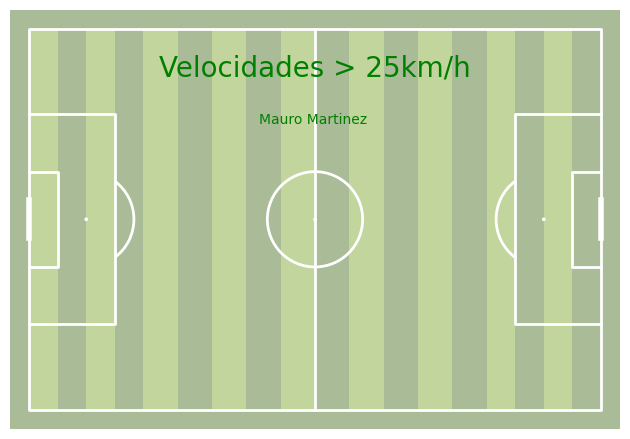

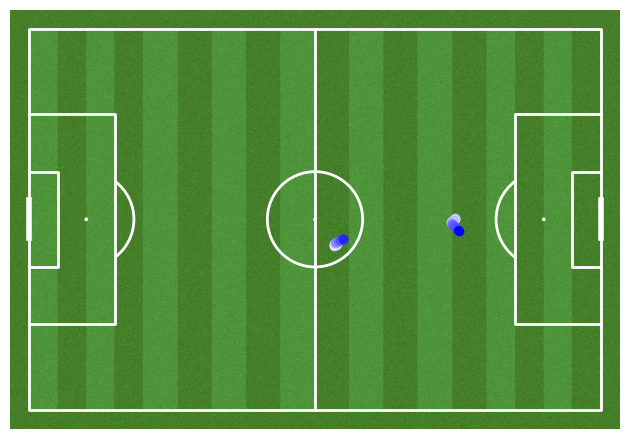

Nahuel Lopez  Total de puntos:  0
El umbral de aceleración se superó 2 veces.
42


/tmp/ipykernel_253/1066697871.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Speed m/s'] = list(df['Speed km/h']/3.6)


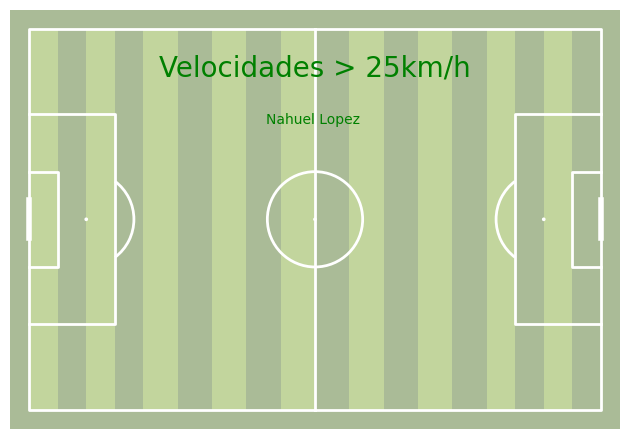

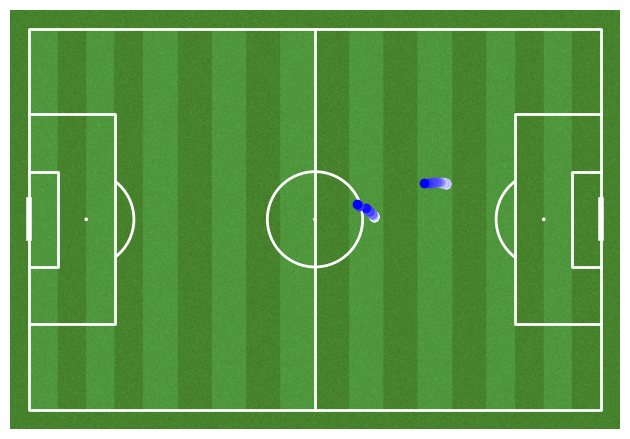

Rodrigo Espalter  Total de puntos:  0
El umbral de aceleración se superó 2 veces.
42


/tmp/ipykernel_253/1066697871.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Speed m/s'] = list(df['Speed km/h']/3.6)


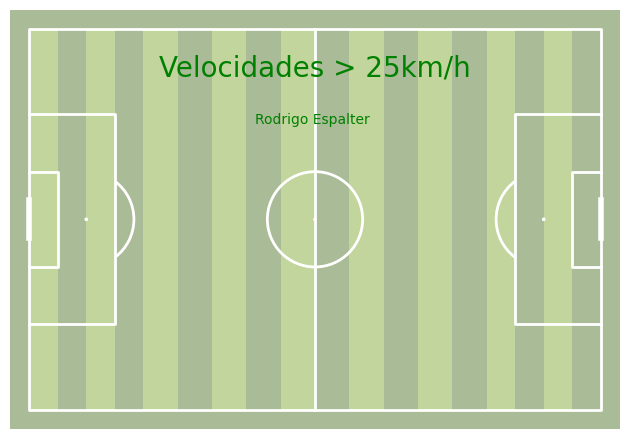

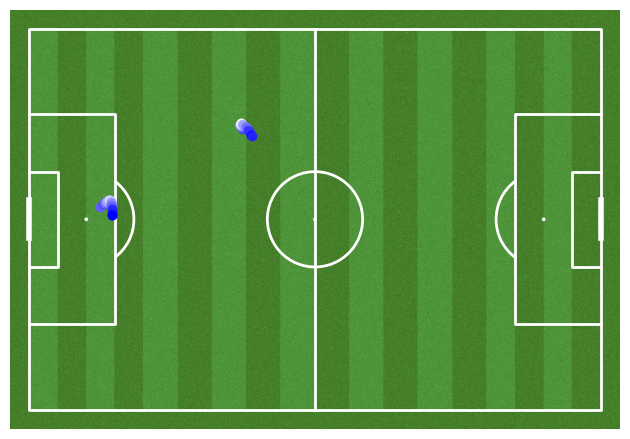

Rodriguez Luciano  Total de puntos:  6
El umbral de aceleración se superó 2 veces.
42


/tmp/ipykernel_253/1066697871.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Speed m/s'] = list(df['Speed km/h']/3.6)


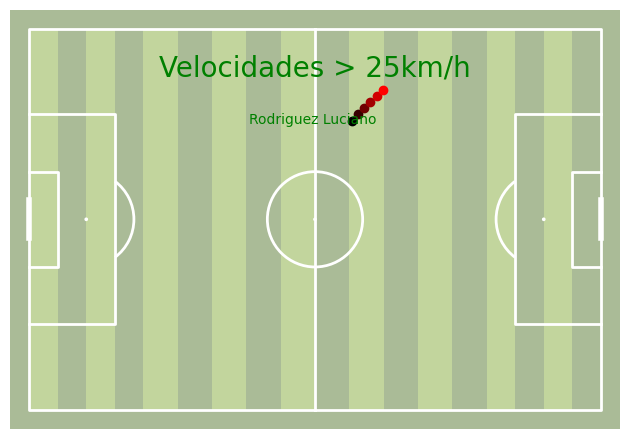

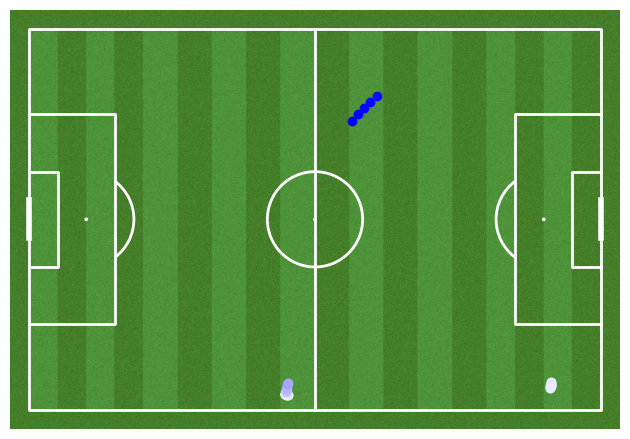

In [96]:
for name, group in df.groupby('Player Display Name'):
    # Filter the group based on 'Player Display Name'
    filtered_group = df[df['Player Display Name'] == name]
    plot_velocidades_altas(25, subtitle=name, use_df=filtered_group)
    plot_aceleraciones_altas(use_df=filtered_group)

Facundo Dominguez  Total de puntos:  0
Fran Dennis  Total de puntos:  0
Mauro Martinez  Total de puntos:  0
Nahuel Lopez  Total de puntos:  0
Rodrigo Espalter  Total de puntos:  0
Rodriguez Luciano  Total de puntos:  6


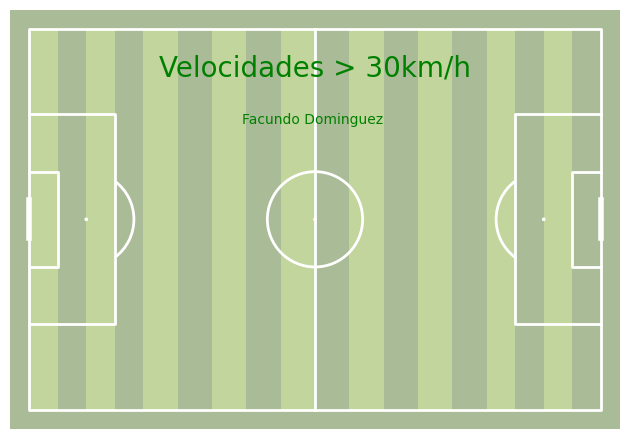

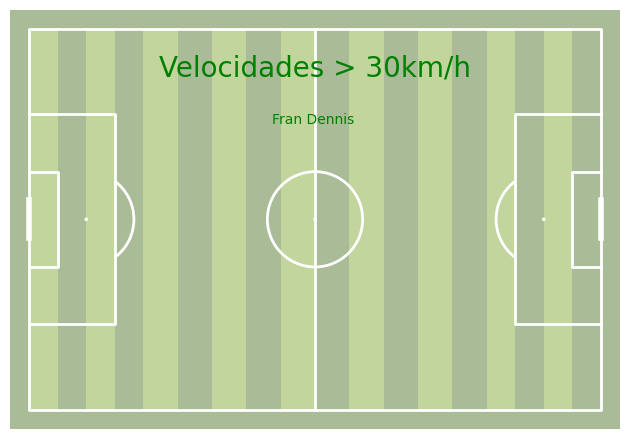

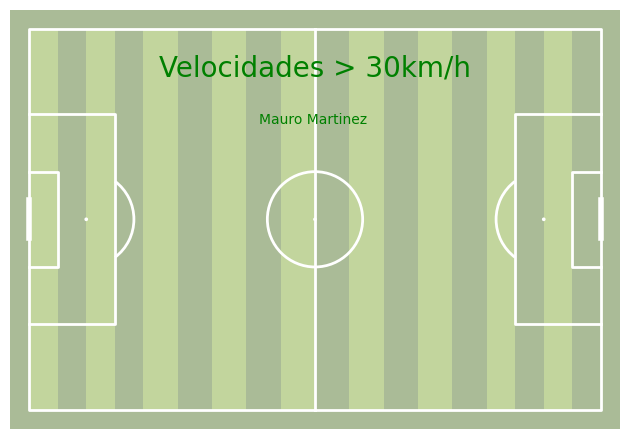

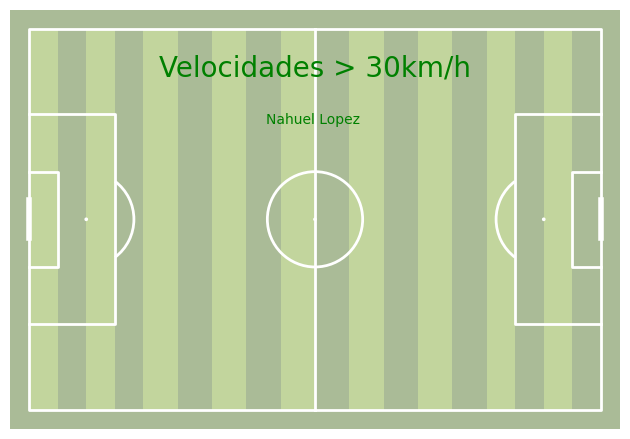

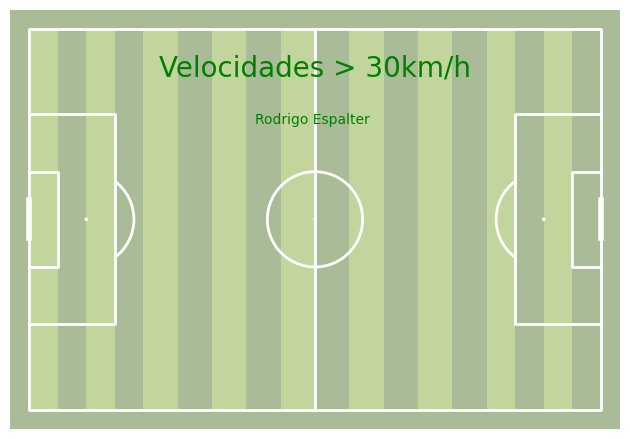

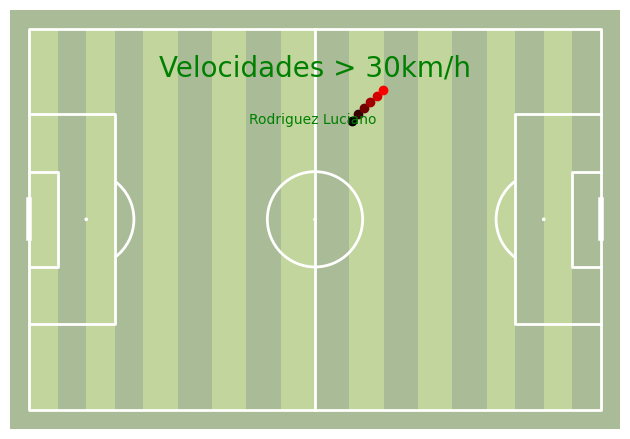

In [97]:
for name, group in df.groupby('Player Display Name'):
    # Filter the group based on 'Player Display Name'
    filtered_group = df[df['Player Display Name'] == name]
    plot_velocidades_altas(30, subtitle=name, use_df=filtered_group)